# Aula 1 · Parte A: scRNA-seq avançado
## Doublets → integração de amostras → anotação automatizada

**Curso:** Análise Avançada de Dados de Single-cell RNA-seq, ATAC-seq e Multiome (10x Genomics) no Google Colab
**Ministrante:** Dra. Cristal Villalba · [github.com/kur1sutaru](https://github.com/kur1sutaru)

---

### O que vamos fazer
| Etapa | Ferramentas | Pergunta que respondemos |
|---|---|---|
| 1. Dados + QC | Scanpy | Dois lotes de PBMC com química 10x diferente (v1 × v3) |
| 2. Doublets | **Scrublet**, **DoubletDetection** (+ scDblFinder em R, opcional) | Os métodos concordam? Que critério usar? |
| 3. Anotação por célula | **CellTypist** | Que rótulo cada célula recebe *antes* de integrar? |
| 4. Integração | **Harmony**, **BBKNN**, **Scanorama**, **scVI** | Qual remove o efeito de lote sem apagar a biologia? |
| 5. Avaliação | métricas de mistura × conservação | Como comparar métodos com números, não só UMAPs? |
| 6. Anotação refinada | CellTypist + *majority voting*, **decoupler**, **scANVI** (label transfer), `sc.tl.ingest` | Os métodos de anotação concordam? |

> **Antes de começar:** `Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4`.
> O scVI/scANVI roda em CPU também, só que bem mais devagar.

**Convenções das células**
- 🔧 **instalação**: rode uma vez por sessão
- ⚙️ **parâmetros**: tudo o que você pode mudar está concentrado aqui
- 📥 **download**: baixa dados da internet (com cache)

## 0. Instalação 🔧
Fixamos **versões exatas**. É a primeira regra de reprodutibilidade (Aula 2, Parte C).
Se o Colab pedir para *reiniciar a sessão* depois da instalação, reinicie e siga a partir da célula de imports.

In [1]:
%pip install -q scanpy==1.12.4 anndata==0.13.4 scvi-tools==1.5.1 celltypist==1.7.1 decoupler==2.2.0 \
    scrublet==0.2.3 doubletdetection==4.3.0.post1 scanorama==1.7.4 bbknn==1.6.0 harmonypy==2.0.2 scikit-learn==1.7.2 \
    leidenalg==0.12.0 igraph session-info2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


## 1. Imports, parâmetros e sementes ⚙️

In [3]:
import os, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(4, 4))

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DATA = Path(os.environ.get("CURSO_DATA", "/content/data" if IN_COLAB else "data"))
OUT = Path(os.environ.get("CURSO_OUT", "/content/resultados" if IN_COLAB else "resultados"))
DATA.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [6]:
SEED = 42
N_CELLS_10K = 4000          # subamostra do lote v3 para caber no Colab gratuito
N_HVG = 3000
MAX_EPOCHS_SCVI = 200       # ~3 min em T4; use 400 para resultados de publicação
MAX_EPOCHS_SCANVI = 20
EXPECTED_DOUBLET_RATE = 0.06
CELLTYPIST_FINO = "Immune_All_Low.pkl"
CELLTYPIST_GROSSO = "Immune_All_High.pkl"

In [7]:
def fixar_sementes(seed: int = 0):
    """Uma semente para governar todas: Python, NumPy, PyTorch e scvi-tools."""
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import scvi
        scvi.settings.seed = seed      # também fixa torch e lightning
    except ImportError:
        pass

fixar_sementes(SEED)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE}")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


PyTorch 2.11.0+cu130 | dispositivo: cuda


## 2. Dados: dois lotes de PBMC 📥

| Lote | Origem | Química | Células |
|---|---|---|---|
| `pbmc3k_v1` | 10x Genomics (`sc.datasets.pbmc3k`) | 3' v1 | ~2.700 |
| `pbmc10k_v3` | 10x Genomics, PBMC 10k v3 | 3' v3 | subamostra de 4.000 |

Mesmo tecido e mesmos tipos celulares, mas **química e profundidade muito diferentes**: um efeito de lote
técnico clássico. É o cenário ideal para comparar métodos de integração, porque a biologia esperada é conhecida.

In [8]:
!wget -q -U "Mozilla/5.0" -O {DATA}/pbmc_10k_v3_filtered.h5 "https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_10k_v3/pbmc_10k_v3_filtered_feature_bc_matrix.h5"

In [9]:
import urllib.request

def baixar(url: str, destino: Path) -> Path:
    """Download com cache: não baixa de novo se o arquivo já existe."""
    destino = Path(destino)
    if not destino.exists():
        print(f"baixando {destino.name} ...")
        urllib.request.urlretrieve(url, destino)
    return destino

URL_10K = ("https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_10k_v3/"
           "pbmc_10k_v3_filtered_feature_bc_matrix.h5")

a3k = sc.datasets.pbmc3k()
a10k = sc.read_10x_h5(baixar(URL_10K, DATA / "pbmc_10k_v3_filtered.h5"))
a10k.var_names_make_unique(); a3k.var_names_make_unique()
sc.pp.subsample(a10k, n_obs=min(N_CELLS_10K, a10k.n_obs), random_state=SEED)

adata = ad.concat({"pbmc3k_v1": a3k, "pbmc10k_v3": a10k}, label="batch",
                  join="inner", index_unique="-")
del a3k, a10k

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


In [10]:
adata.obs["batch"] = adata.obs["batch"].astype("category")
adata.layers["counts"] = adata.X.copy()          # SEMPRE guarde as contagens cruas
print(adata)
adata.obs["batch"].value_counts()

AnnData object with n_obs × n_vars = 6700 × 20453
    obs: 'batch'
    layers: None (.X), 'counts'


batch
pbmc10k_v3    4000
pbmc3k_v1     2700
Name: count, dtype: int64

## 3. Controle de qualidade (revisão rápida)
Já vimos no módulo introdutório; aqui só reforçamos um ponto: **o QC deve ser feito por lote**,
porque as distribuições de UMIs mudam com a química.

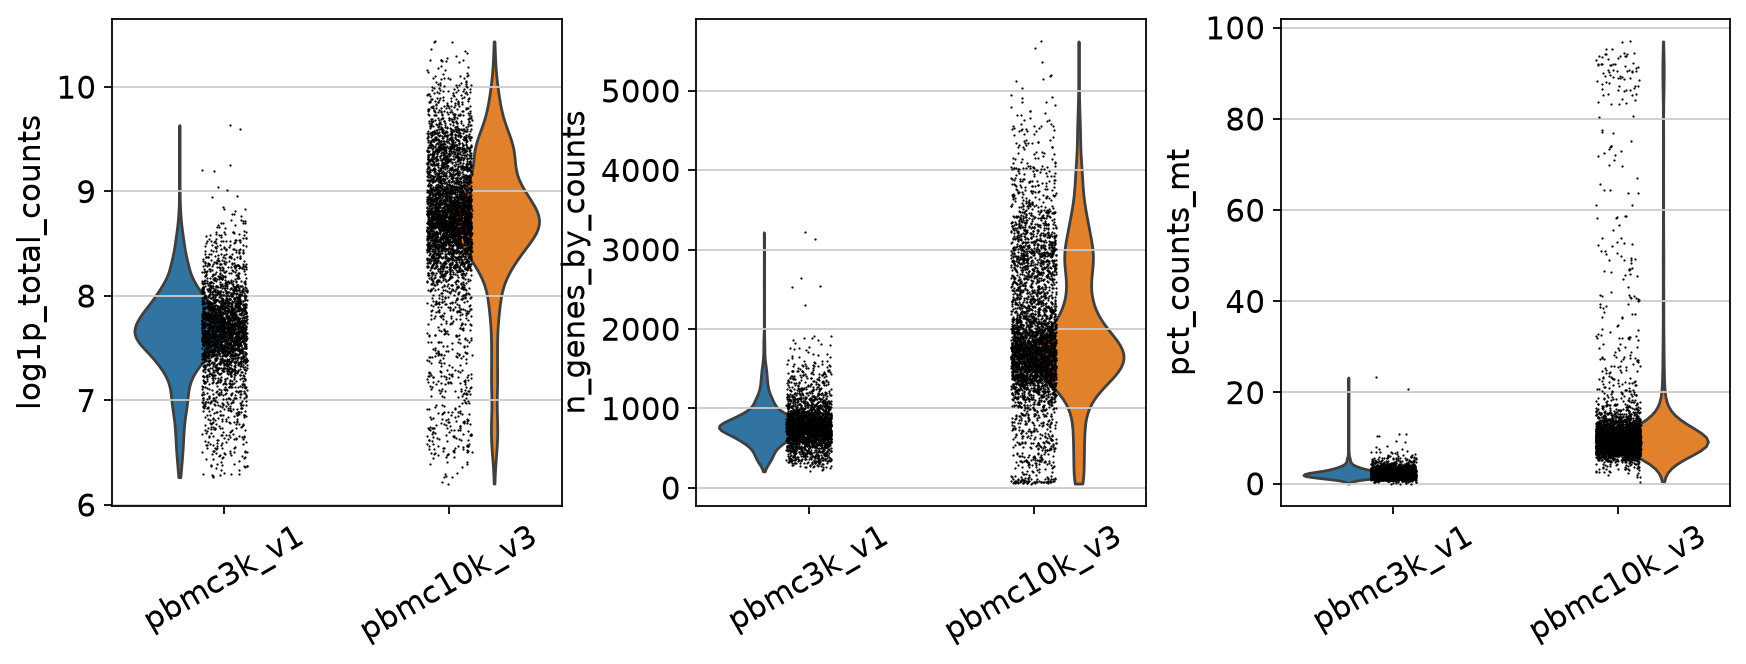

In [11]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"], percent_top=None, log1p=True, inplace=True)

sc.pl.violin(adata, ["log1p_total_counts", "n_genes_by_counts", "pct_counts_mt"],
             groupby="batch", multi_panel=True, rotation=30)

In [12]:
def filtro_mad(x: pd.Series, nmads: float = 5) -> pd.Series:
    """Outlier se estiver a mais de `nmads` desvios absolutos medianos da mediana."""
    mad = (x - x.median()).abs().median()
    return (x < x.median() - nmads * mad) | (x > x.median() + nmads * mad)

outlier = np.zeros(adata.n_obs, dtype=bool)
for b, idx in adata.obs.groupby("batch", observed=True).indices.items():
    o = adata.obs.iloc[idx]
    outlier[idx] = (filtro_mad(o["log1p_total_counts"]) | filtro_mad(o["log1p_n_genes_by_counts"])
                    | (o["pct_counts_mt"] > 15)).values
adata.obs["qc_outlier"] = outlier
print(adata.obs.groupby("batch", observed=True)["qc_outlier"].mean().rename("fração removida"))

adata = adata[~adata.obs["qc_outlier"]].copy()
sc.pp.filter_genes(adata, min_cells=10)
adata

batch
pbmc3k_v1     0.031852
pbmc10k_v3    0.112250
Name: fração removida, dtype: float64


AnnData object with n_obs × n_vars = 6165 × 12779
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'qc_outlier'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'batch_colors'
    layers: None (.X), 'counts'

## 4. Detecção de doublets

Doublets = duas células no mesmo *droplet*. Na 10x, a taxa esperada é ~0,8% a cada 1.000 células recuperadas.

| Método | Ideia | Linguagem |
|---|---|---|
| **Scrublet** | simula doublets somando pares de células e mede quantos vizinhos simulados cada célula real tem | Python (dentro do Scanpy) |
| **DoubletDetection** | simula doublets várias vezes, clusteriza e testa (hipergeométrico) se a célula cai em clusters ricos em doublets | Python |
| **scDblFinder** | simulação + classificador (gradient boosting) em várias features; costuma liderar benchmarks | R/Bioconductor |

**Regra de ouro:** rode **por lote** (`batch_key`), porque doublets só existem dentro do mesmo canal 10x.

In [13]:
sc.pp.scrublet(adata, batch_key="batch", expected_doublet_rate=EXPECTED_DOUBLET_RATE,
               random_state=SEED, verbose=False)
adata.obs["dbl_scrublet"] = adata.obs["predicted_doublet"].astype(bool)
adata.obs.groupby("batch", observed=True)["dbl_scrublet"].mean()

batch
pbmc3k_v1     0.015685
pbmc10k_v3    0.045058
Name: dbl_scrublet, dtype: float64

In [14]:
import doubletdetection

dd_labels = np.zeros(adata.n_obs, dtype=bool)
dd_scores = np.zeros(adata.n_obs)
for b, idx in adata.obs.groupby("batch", observed=True).indices.items():
    clf = doubletdetection.BoostClassifier(
        n_iters=10, clustering_algorithm="leiden", standard_scaling=True,
        random_state=SEED, verbose=False)
    clf.fit(adata.layers["counts"][idx])
    dd_labels[idx] = clf.predict(p_thresh=1e-16, voter_thresh=0.5).astype(bool)
    dd_scores[idx] = clf.doublet_score()
adata.obs["dbl_doubletdetection"] = dd_labels
adata.obs["dd_score"] = dd_scores
adata.obs.groupby("batch", observed=True)["dbl_doubletdetection"].mean()

/usr/local/lib/python3.13/dist-packages/doubletdetection/doubletdetection.py:106: UserWarning: Leiden clustering is experimental and results have not been validated.
  warnings.warn("Leiden clustering is experimental and results have not been validated.")


  0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/doubletdetection/doubletdetection.py:106: UserWarning: Leiden clustering is experimental and results have not been validated.
  warnings.warn("Leiden clustering is experimental and results have not been validated.")


  0%|          | 0/10 [00:00<?, ?it/s]

batch
pbmc3k_v1     0.003060
pbmc10k_v3    0.050127
Name: dbl_doubletdetection, dtype: float64

### Os métodos concordam?

In [15]:
tab = pd.crosstab(adata.obs["dbl_scrublet"], adata.obs["dbl_doubletdetection"],
                  rownames=["Scrublet"], colnames=["DoubletDetection"])
inter = (adata.obs["dbl_scrublet"] & adata.obs["dbl_doubletdetection"]).sum()
uniao = (adata.obs["dbl_scrublet"] | adata.obs["dbl_doubletdetection"]).sum()
print(f"Jaccard entre métodos: {inter / max(uniao, 1):.2f}")
tab

Jaccard entre métodos: 0.55


DoubletDetection,False,True
Scrublet,,
False,5915,49
True,64,137


> 💬 **Discussão:** a concordância costuma ser **baixa**. Estratégias comuns:
> 1. **conservadora**: remover só o consenso (interseção);
> 2. **agressiva**: remover a união;
> 3. **dirigida pela biologia**: manter as chamadas, clusterizar e remover *clusters* com co-expressão de marcadores
>    incompatíveis (ex.: `CD3E` + `CD79A`) e alto score.
>
> Aqui vamos marcar e **remover a interseção**, e conferir os clusters suspeitos depois.

In [16]:
adata.obs["doublet_consenso"] = adata.obs["dbl_scrublet"] & adata.obs["dbl_doubletdetection"]
print(f"Removendo {adata.obs['doublet_consenso'].sum()} doublets de consenso")
adata = adata[~adata.obs["doublet_consenso"]].copy()

Removendo 137 doublets de consenso


### (Opcional, ~10 min de instalação) scDblFinder via R
O Colab tem R instalado. Exportamos a matriz de contagens e chamamos o `scDblFinder` por linha de comando.
Deixe para fazer em casa: a instalação do Bioconductor compila pacotes.

In [ ]:
RODAR_SCDBLFINDER = False

if RODAR_SCDBLFINDER:
    import scipy.io, subprocess
    tmp = DATA / "scdbl"; tmp.mkdir(exist_ok=True)
    scipy.io.mmwrite(tmp / "counts.mtx", adata.layers["counts"].T.tocsr())   # genes × células
    adata.obs[["batch"]].to_csv(tmp / "cells.csv")
    (tmp / "run.R").write_text("""
if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager")
for (p in c("scDblFinder","SingleCellExperiment")) if (!requireNamespace(p, quietly=TRUE)) BiocManager::install(p, ask=FALSE)
suppressMessages({library(Matrix); library(SingleCellExperiment); library(scDblFinder)})
m <- as(readMM("counts.mtx"), "CsparseMatrix"); cells <- read.csv("cells.csv", row.names=1)
colnames(m) <- rownames(cells)
sce <- SingleCellExperiment(list(counts=m))
sce <- scDblFinder(sce, samples=cells$batch)
write.csv(data.frame(cell=colnames(sce), score=sce$scDblFinder.score, class=sce$scDblFinder.class),
          "scdblfinder.csv", row.names=FALSE)
""")
    subprocess.run(["Rscript", "run.R"], cwd=tmp, check=True)
    r = pd.read_csv(tmp / "scdblfinder.csv", index_col="cell")
    adata.obs["dbl_scdblfinder"] = r.loc[adata.obs_names, "class"].eq("doublet").values

## 5. Normalização, HVGs e PCA *sem* correção

In [13]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata                                    # log-normalizado, todos os genes
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat_v3",
                            layer="counts", batch_key="batch")
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable", random_state=SEED)

## 6. Anotação por célula com CellTypist (antes da integração!) 📥

O CellTypist é um **classificador** (regressão logística) treinado em atlas de referência.
Ele classifica cada célula **de forma independente** a partir da expressão log-normalizada (10.000 contagens),
por isso **não depende da integração**. Isso nos dá rótulos para *avaliar* os métodos de integração.

- `Immune_All_High`: ~30 tipos (grosso) → usado nas métricas
- `Immune_All_Low`: ~100 subtipos (fino)

In [14]:
import sys
# cudf/cuml do Colab (RAPIDS) são incompatíveis com o pandas atual e não usamos no curso
for m in ("cudf", "cuml"):
    sys.modules[m] = None   # faz "import cudf" falhar limpo; as libs seguem sem ele

import celltypist
from celltypist import models

In [15]:
import celltypist
from celltypist import models

models.download_models(model=[CELLTYPIST_FINO, CELLTYPIST_GROSSO], force_update=False)
modelo_fino = models.Model.load(CELLTYPIST_FINO)
modelo_grosso = models.Model.load(CELLTYPIST_GROSSO)

In [16]:
adata_ct = adata.raw.to_adata()        # CellTypist quer log1p(CP10k) com TODOS os genes
pred_g = celltypist.annotate(adata_ct, model=modelo_grosso, majority_voting=False)
pred_f = celltypist.annotate(adata_ct, model=modelo_fino, majority_voting=False)
adata.obs["ct_grosso"] = pred_g.predicted_labels["predicted_labels"].astype("category")
adata.obs["ct_fino"] = pred_f.predicted_labels["predicted_labels"].astype("category")
adata.obs["ct_conf"] = pred_f.probability_matrix.max(axis=1).values

pd.crosstab(adata.obs["ct_grosso"], adata.obs["batch"])

batch,pbmc3k_v1,pbmc10k_v3
ct_grosso,,
B cells,332,494
Cycling cells,0,1
DC,22,60
ETP,0,1
HSC/MPP,2,0
ILC,190,208
MNP,1,0
Macrophages,8,1
Megakaryocyte precursor,1,1


## 7. Integração: quatro estratégias diferentes

| Método | Corrige o quê? | Saída | Contagens corrigidas? |
|---|---|---|---|
| **Harmony** | o *embedding* (PCA), com clusterização suave iterativa | `X_pca_harmony` | não |
| **BBKNN** | o *grafo* de vizinhos: k vizinhos buscados **em cada lote** | grafo | não |
| **Scanorama** | o *embedding*, via vizinhos mútuos entre lotes (estilo "panorama") | `X_scanorama` | opcional |
| **scVI** | modelo generativo (VAE) com o lote como covariável | `X_scVI` latente | sim (`get_normalized_expression`) |

Para cada método calculamos o grafo kNN + UMAP e guardamos com um nome próprio.

In [17]:
def grafo_e_umap(adata, nome, use_rep=None, bbknn=False):
    """Calcula vizinhos + UMAP e guarda em obsp/obsm com o sufixo `nome`."""
    if bbknn:
        sc.external.pp.bbknn(adata, batch_key="batch", use_rep="X_pca", n_pcs=30)
    else:
        sc.pp.neighbors(adata, use_rep=use_rep, n_neighbors=15, random_state=SEED)
    sc.tl.umap(adata, random_state=SEED)
    adata.obsp[f"{nome}_connectivities"] = adata.obsp["connectivities"].copy()
    adata.obsm[f"X_umap_{nome}"] = adata.obsm["X_umap"].copy()

grafo_e_umap(adata, "sem_correcao", use_rep="X_pca")

In [18]:
# Harmony: chamamos o harmonypy diretamente.
# ⚠️ Lição de manutenção: o harmonypy 2.0 mudou a orientação de `Z_corr` (agora células × dims) e o wrapper
# `sc.external.pp.harmony_integrate` do Scanpy 1.12 ainda transpõe, o que gera erro de dimensão.
# Conferir a forma da matriz nos protege dos dois comportamentos.
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, "batch", random_state=SEED, verbose=False)
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
grafo_e_umap(adata, "harmony", use_rep="X_pca_harmony")

# BBKNN
grafo_e_umap(adata, "bbknn", bbknn=True)

# Scanorama: exige que as células de cada lote estejam CONTÍGUAS
assert adata.obs["batch"].is_monotonic_increasing or adata.obs["batch"].cat.codes.diff().fillna(0).ge(0).all()
sc.external.pp.scanorama_integrate(adata, key="batch", basis="X_pca", adjusted_basis="X_scanorama")
grafo_e_umap(adata, "scanorama", use_rep="X_scanorama")

[[0.         0.74215761]
 [0.         0.        ]]
Processing datasets pbmc3k_v1 <=> pbmc10k_v3


### scVI: integração com modelo generativo
O scVI recebe **contagens cruas** (não log!) e modela cada gene com uma binomial negativa.
O lote entra como covariável, e o espaço latente aprende a variação *que não é explicada pelo lote*.

In [19]:
import scvi

adata_hvg = adata[:, adata.var["highly_variable"]].copy()
scvi.model.SCVI.setup_anndata(adata_hvg, layer="counts", batch_key="batch")
vae = scvi.model.SCVI(adata_hvg, n_layers=2, n_latent=30, gene_likelihood="nb")
vae.train(max_epochs=MAX_EPOCHS_SCVI, early_stopping=True, accelerator="auto")
adata.obsm["X_scVI"] = vae.get_latent_representation()
grafo_e_umap(adata, "scvi", use_rep="X_scVI")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/200 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=200` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=200` reached.


In [20]:
%matplotlib inline
import matplotlib
print(matplotlib.get_backend())   # deve mostrar algo com "inline"

module://matplotlib_inline.backend_inline


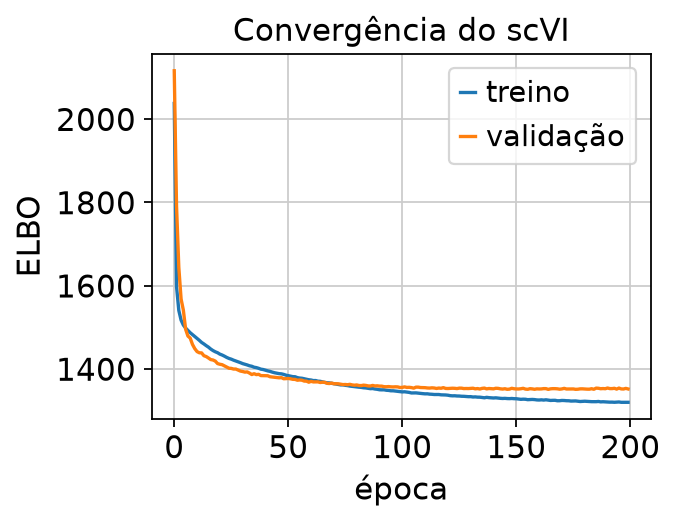

In [21]:
hist = vae.history
plt.figure(figsize=(4, 3))
plt.plot(hist["elbo_train"], label="treino")
if "elbo_validation" in hist:
    plt.plot(hist["elbo_validation"], label="validação")
plt.xlabel("época"); plt.ylabel("ELBO"); plt.legend(); plt.title("Convergência do scVI")
plt.show()

### Comparação visual

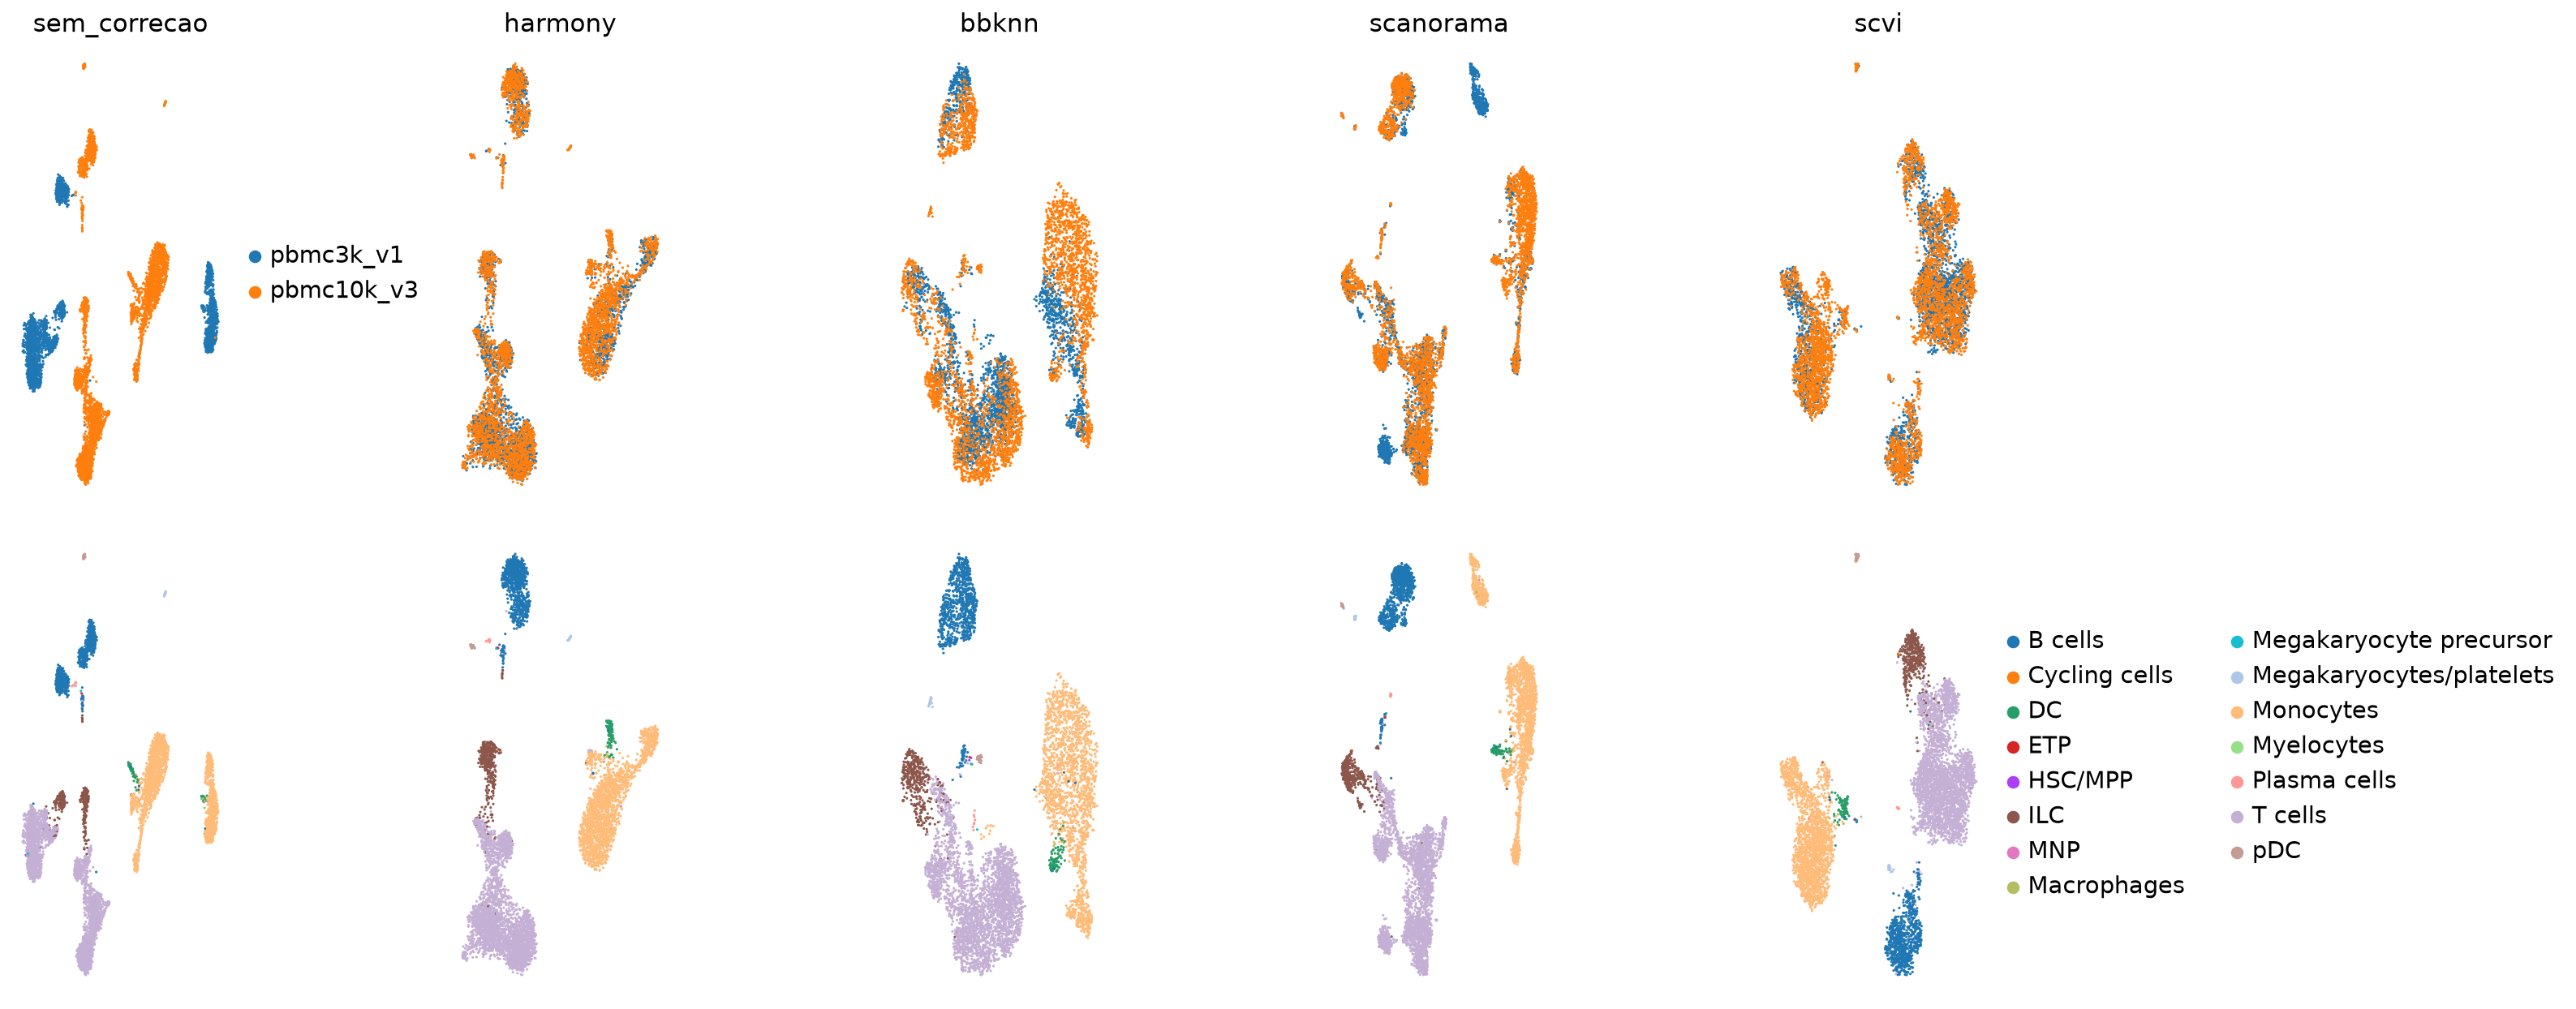

In [22]:
METODOS = ["sem_correcao", "harmony", "bbknn", "scanorama", "scvi"]
fig, axes = plt.subplots(2, len(METODOS), figsize=(4 * len(METODOS), 8))
for j, m in enumerate(METODOS):
    sc.pl.embedding(adata, basis=f"X_umap_{m}", color="batch", ax=axes[0, j], show=False,
                    title=m, legend_loc=None if j else "right margin", size=8)
    sc.pl.embedding(adata, basis=f"X_umap_{m}", color="ct_grosso", ax=axes[1, j], show=False,
                    title="", legend_loc=None if j < len(METODOS) - 1 else "right margin", size=8)
plt.tight_layout(); plt.show()

## 8. Avaliação quantitativa da integração

UMAP engana. Medimos **dois objetivos que competem entre si**:

- **Mistura de lotes** (↑ melhor): entropia normalizada dos lotes entre os k vizinhos de cada célula
  (parente do *iLISI*). 1 = vizinhança perfeitamente misturada.
- **Conservação biológica** (↑ melhor): fração de vizinhos com o mesmo tipo celular (*kNN purity*, parente do *cLISI*).

Um método que "mistura tudo" ganha em mistura e perde em conservação. O ideal é ficar alto nos dois.
Para o benchmark completo, veja o pacote [`scib-metrics`](https://scib-metrics.readthedocs.io).

In [1]:
!pip install -q -U "matplotlib>=3.10.5"

In [23]:
def metricas_grafo(adata, nome, batch_key="batch", label_key="ct_grosso"):
    G = adata.obsp[f"{nome}_connectivities"].tocsr()
    b = adata.obs[batch_key].cat.codes.values
    lab = adata.obs[label_key].cat.codes.values
    nb = len(np.unique(b))
    # entropia de lote esperada no dataset (limite superior realista)
    p_glob = np.bincount(b) / len(b)
    h_max = -(p_glob * np.log(p_glob)).sum()
    ent, pur = [], []
    for i in range(adata.n_obs):
        viz = G.indices[G.indptr[i]:G.indptr[i + 1]]
        if len(viz) == 0:
            continue
        p = np.bincount(b[viz], minlength=nb) / len(viz)
        p = p[p > 0]
        ent.append(-(p * np.log(p)).sum() / h_max)
        pur.append((lab[viz] == lab[i]).mean())
    return {"metodo": nome, "mistura_lotes": np.mean(ent), "conservacao_tipo": np.mean(pur)}

res = pd.DataFrame([metricas_grafo(adata, m) for m in METODOS]).set_index("metodo")
res["media"] = res.mean(axis=1)
res.sort_values("media", ascending=False).style.background_gradient(cmap="Greens").format("{:.3f}")

,mistura_lotes,conservacao_tipo,media
metodo,,,
bbknn,0.843,0.972,0.907
scvi,0.832,0.965,0.898
harmony,0.659,0.977,0.818
scanorama,0.582,0.972,0.777
sem_correcao,0.028,0.975,0.502


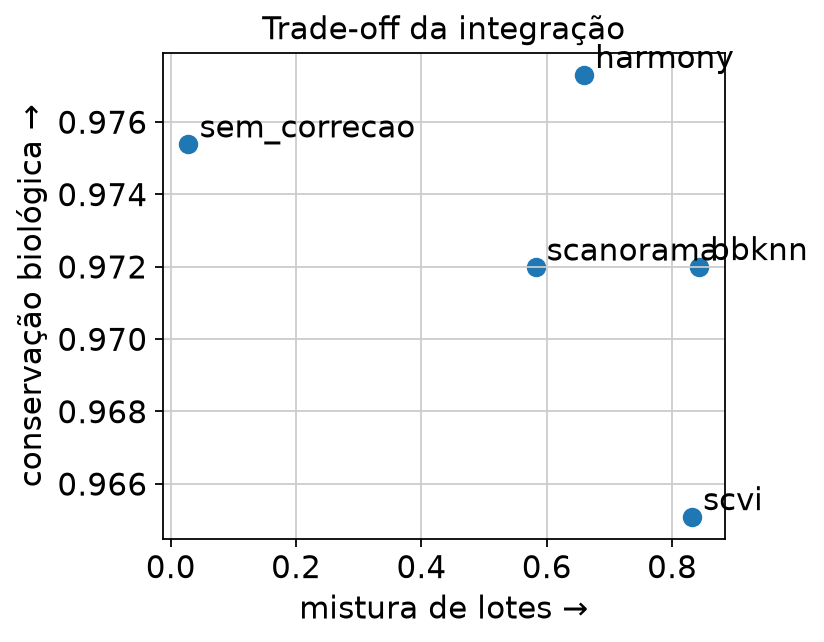

In [24]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(res["mistura_lotes"], res["conservacao_tipo"], s=60)
for m, r in res.iterrows():
    ax.annotate(m, (r["mistura_lotes"], r["conservacao_tipo"]), xytext=(5, 3), textcoords="offset points")
ax.set_xlabel("mistura de lotes →"); ax.set_ylabel("conservação biológica →")
ax.set_title("Trade-off da integração"); plt.show()

> 💬 **Discussão:** não existe método universalmente melhor (Luecken et al., *Nat Methods* 2022).
> - Poucos lotes e tipos celulares bem separados → **Harmony** costuma bastar, e é rápido.
> - Muitos lotes, composição celular diferente entre lotes, atlas → **scVI/scANVI**.
> - Precisa de um grafo para clusterizar e quer algo leve → **BBKNN**.
> - **Nunca** use dados integrados para expressão diferencial: use contagens cruas + lote como covariável.

## 9. Anotação refinada

### 9.1 CellTypist + *majority voting*
Rótulos por célula são ruidosos. O *majority voting* atribui a cada **cluster** (sobre-clusterizado) o rótulo mais votado.
Usamos os clusters do espaço integrado pelo scVI.

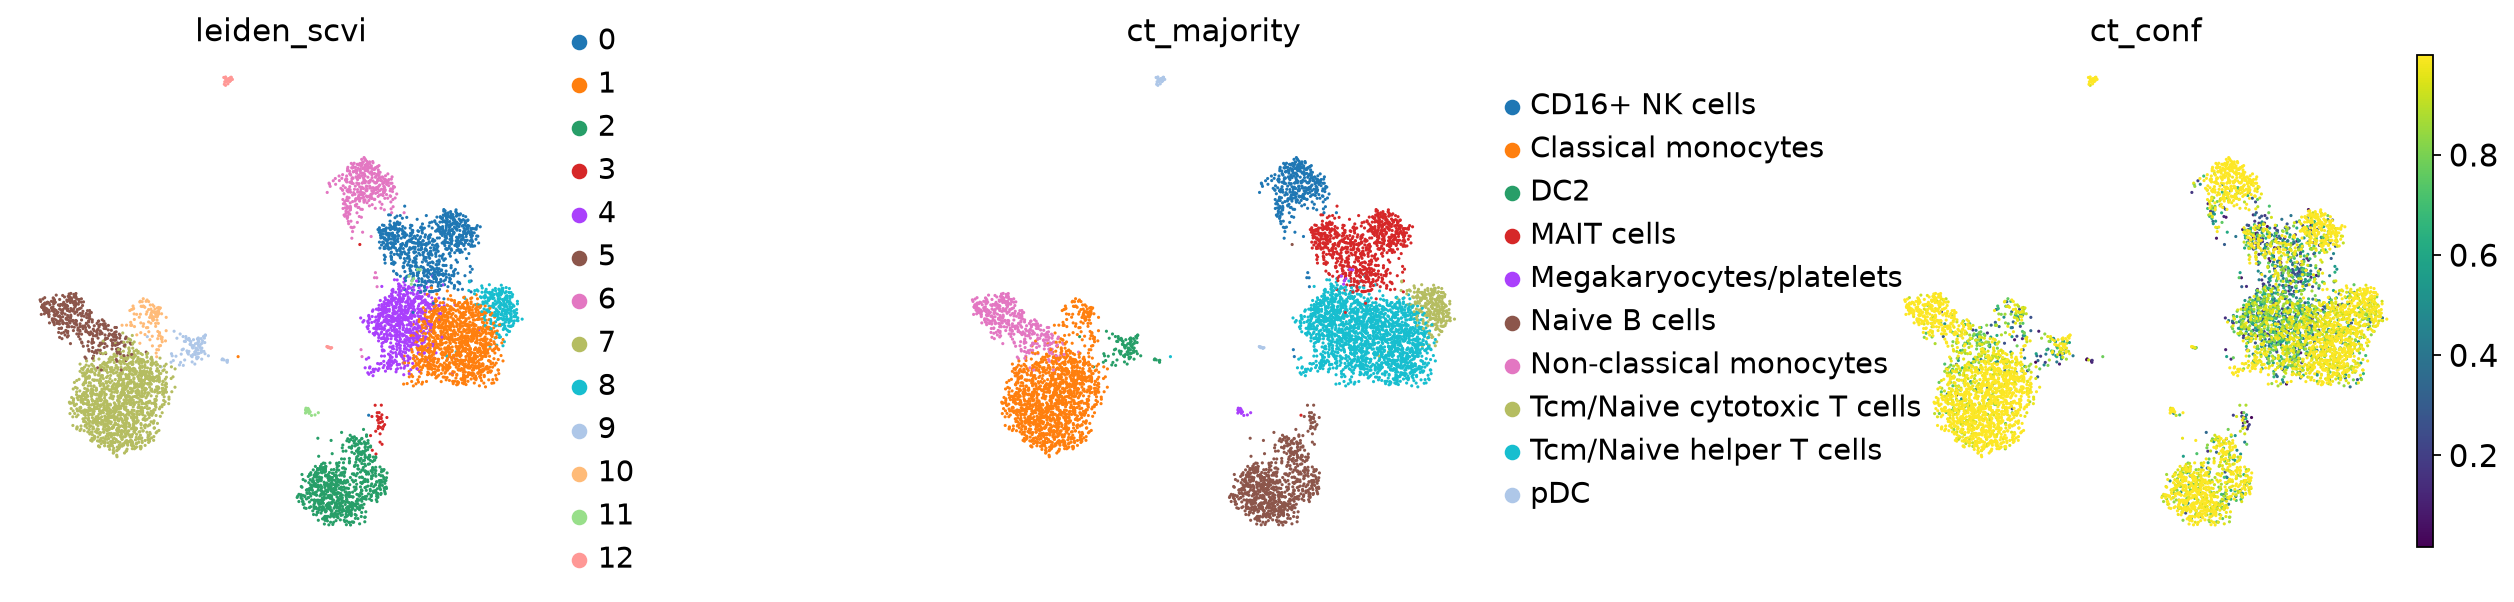

In [25]:
sc.pp.neighbors(adata, use_rep="X_scVI", random_state=SEED)          # restaura o grafo scVI completo
adata.obsm["X_umap"] = adata.obsm["X_umap_scvi"]
sc.tl.leiden(adata, resolution=1.0, key_added="leiden_scvi", random_state=SEED,
             flavor="igraph", n_iterations=2, directed=False)

pred_mv = celltypist.annotate(adata_ct, model=modelo_fino, majority_voting=True,
                              over_clustering=adata.obs["leiden_scvi"].astype(str).values)
adata.obs["ct_majority"] = pred_mv.predicted_labels["majority_voting"].astype("category")
sc.pl.umap(adata, color=["leiden_scvi", "ct_majority", "ct_conf"], ncols=3, wspace=0.6, size=8)

### 9.2 Validação independente: *scoring* de assinaturas com decoupler
Uma anotação por classificador deve ser **conferida com marcadores**. O `decoupler` calcula, para cada célula,
um score de enriquecimento (aqui, **ULM**: regressão linear univariada) de cada conjunto de marcadores.

Usamos um painel curado de PBMC. Em seguida, o mesmo cálculo com o recurso **PanglaoDB** (via OmniPath).

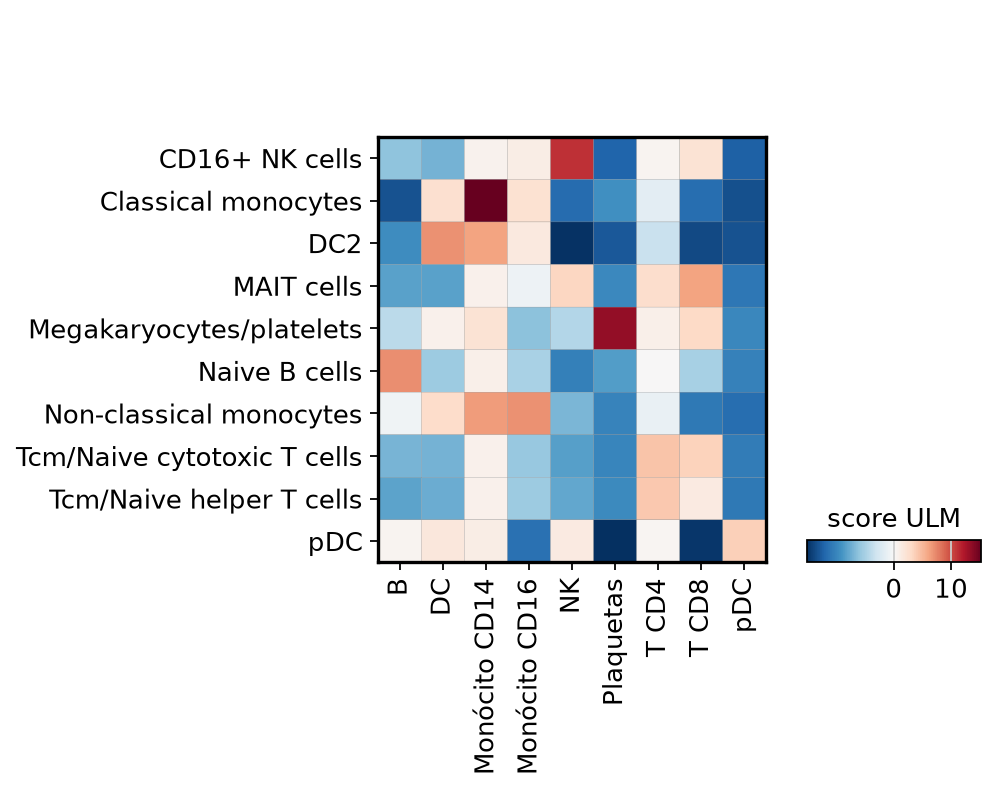

In [26]:
import decoupler as dc

MARCADORES_PBMC = {
    "T CD4": ["CD3E", "CD4", "IL7R", "CCR7", "LEF1", "TCF7"],
    "T CD8":           ["CD3E", "CD8A", "CD8B", "GZMK", "CCL5"],
    "NK":              ["GNLY", "NKG7", "KLRD1", "PRF1", "GZMB", "NCAM1"],
    "B":               ["MS4A1", "CD79A", "CD79B", "BANK1", "PAX5"],
    "Monócito CD14":   ["CD14", "LYZ", "S100A8", "S100A9", "VCAN"],
    "Monócito CD16":   ["FCGR3A", "MS4A7", "LST1", "CDKN1C"],
    "DC":              ["FCER1A", "CST3", "CLEC10A", "CD1C"],
    "pDC":             ["LILRA4", "IL3RA", "CLEC4C"],
    "Plaquetas":       ["PPBP", "PF4", "GP9"],
}
net_pbmc = pd.DataFrame([(ct, g) for ct, gs in MARCADORES_PBMC.items() for g in gs],
                        columns=["source", "target"])

dc.mt.ulm(adata, net_pbmc, tmin=3, raw=True)          # usa adata.raw (log-normalizado)
scores = dc.pp.get_obsm(adata, key="score_ulm")
sc.pl.matrixplot(scores, var_names=scores.var_names, groupby="ct_majority",
                 cmap="RdBu_r", vcenter=0, colorbar_title="score ULM", dendrogram=False)

In [27]:
rank = dc.tl.rankby_group(scores, groupby="leiden_scvi", reference="rest", method="t-test_overestim_var")
melhor = (rank[rank["stat"] > 0].groupby("group").head(1).set_index("group")["name"])
adata.obs["ct_marcadores"] = adata.obs["leiden_scvi"].astype(str).map(melhor.astype(str).to_dict()).astype("category")
pd.crosstab(adata.obs["ct_marcadores"], adata.obs["ct_grosso"]).style.background_gradient(axis=1)

ct_grosso,B cells,Cycling cells,DC,ETP,HSC/MPP,ILC,MNP,Macrophages,Megakaryocyte precursor,Megakaryocytes/platelets,Monocytes,Myelocytes,Plasma cells,T cells,pDC
ct_marcadores,,,,,,,,,,,,,,,
B,817,0,0,0,0,0,0,0,0,0,0,0,0,8,0
DC,2,0,80,1,2,0,0,4,2,0,6,0,0,0,0
Monócito CD14,3,0,2,0,0,1,1,5,0,0,1447,2,0,5,0
Monócito CD16,0,0,0,0,0,0,0,0,0,0,398,0,0,0,0
NK,0,1,0,0,0,357,0,0,0,0,0,0,0,7,0
Plaquetas,0,0,0,0,0,0,0,0,0,18,0,0,0,6,0
T CD4,2,0,0,0,0,0,0,0,0,0,0,0,0,2154,0
T CD8,2,0,0,0,0,40,0,0,0,0,0,0,0,758,0
pDC,0,0,0,0,0,0,0,0,0,0,1,0,8,0,25


In [28]:
# PanglaoDB via OmniPath (requer internet). Filtramos marcadores canônicos e sensíveis em humanos.
try:
    panglao = dc.op.resource("PanglaoDB", organism="human")
    gcol = "genesymbol" if "genesymbol" in panglao.columns else panglao.columns[0]
    sel = panglao[panglao["canonical_marker"].astype(str).isin(["True", "true", "1"])
                  & (pd.to_numeric(panglao["human_sensitivity"], errors="coerce") > 0.5)]
    net_panglao = (sel.rename(columns={"cell_type": "source", gcol: "target"})[["source", "target"]]
                   .drop_duplicates())
except Exception as e:                       # sem internet / API mudou: seguimos sem o PanglaoDB
    print("PanglaoDB indisponível:", e); net_panglao = None

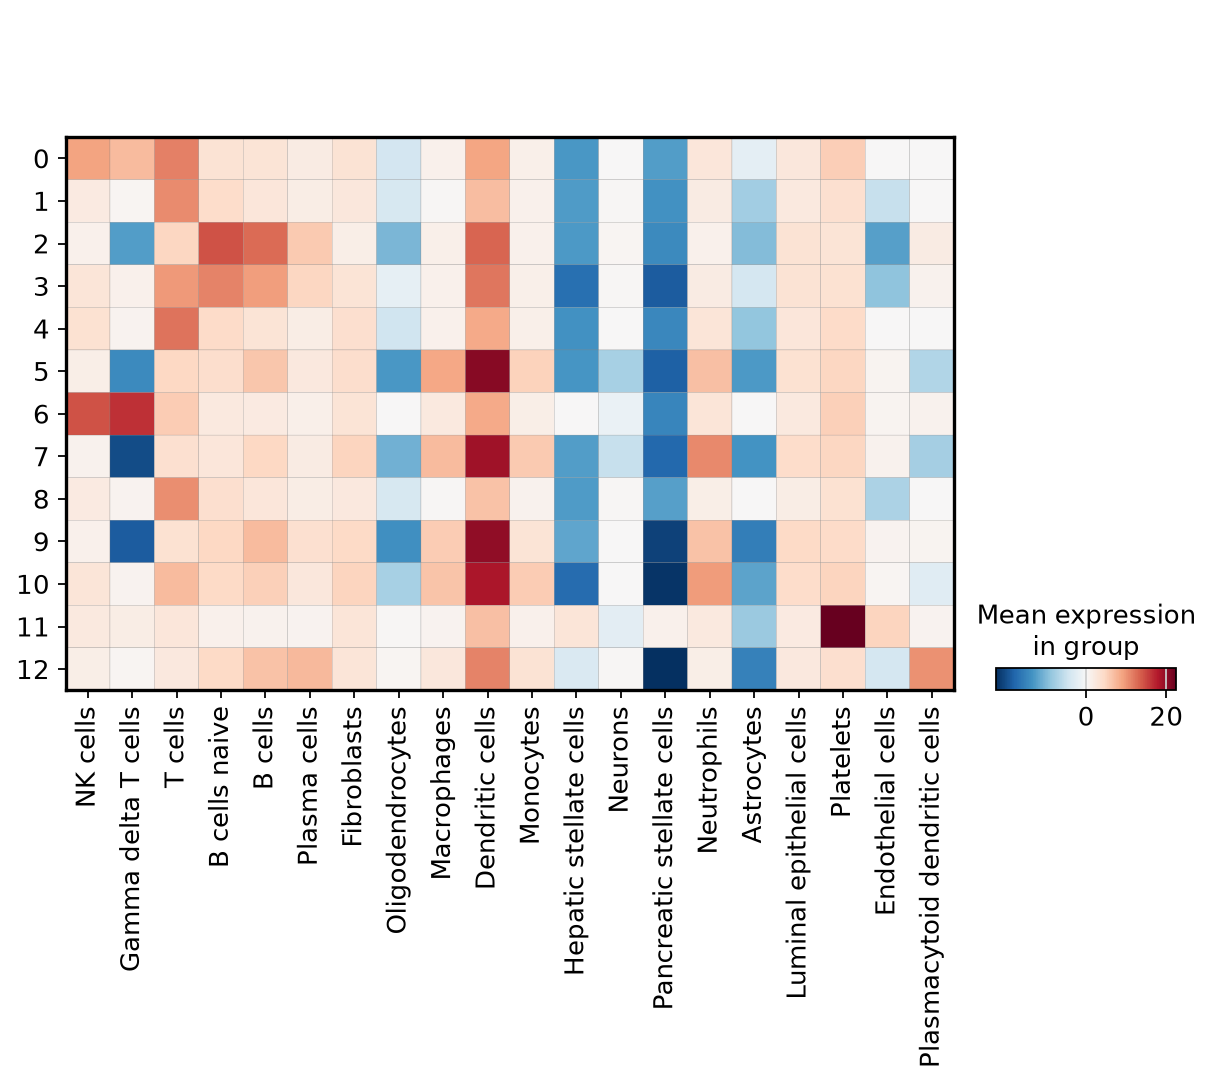

In [29]:
if net_panglao is not None:
    dc.mt.ulm(adata, net_panglao, tmin=5, raw=True)
    sc_pg = dc.pp.get_obsm(adata, key="score_ulm")
    rk = dc.tl.rankby_group(sc_pg, groupby="leiden_scvi", reference="rest", method="t-test_overestim_var")
    top = rk[rk["stat"] > 0].groupby("group").head(3)
    sc.pl.matrixplot(sc_pg, var_names=top["name"].unique(), groupby="leiden_scvi",
                     cmap="RdBu_r", vcenter=0, standard_scale=None)

### 9.3 *Label transfer*: referência → consulta

Cenário real: você tem uma **referência anotada** e quer rotular uma **consulta** nova.
Aqui: referência = lote `pbmc10k_v3` (rótulos do CellTypist); consulta = `pbmc3k_v1`, tratada como **não anotada**.

Duas abordagens:
1. **`sc.tl.ingest`**: projeta a consulta no PCA/UMAP da referência e transfere rótulos por kNN. Simples e rápido; supõe pouco efeito de lote.
2. **scANVI**: estende o scVI com rótulos (semi-supervisionado) e prediz as células "Unknown". Lida com efeito de lote.

In [30]:
REF, QUERY = "pbmc10k_v3", "pbmc3k_v1"
adata.obs["ref_label"] = np.where(adata.obs["batch"] == REF, adata.obs["ct_grosso"].astype(str), "Unknown")
adata_hvg.obs["ref_label"] = adata.obs["ref_label"].values

lvae = scvi.model.SCANVI.from_scvi_model(vae, unlabeled_category="Unknown",
                                         labels_key="ref_label", adata=adata_hvg)
lvae.train(max_epochs=MAX_EPOCHS_SCANVI, n_samples_per_label=100, accelerator="auto")
adata.obs["scanvi_pred"] = pd.Categorical(lvae.predict(adata_hvg))
adata.obsm["X_scANVI"] = lvae.get_latent_representation(adata_hvg)

INFO     Training for 20 epochs.                                                                                   


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/20 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


In [31]:
ref = adata[adata.obs["batch"] == REF, adata.var["highly_variable"]].copy()
qry = adata[adata.obs["batch"] == QUERY, adata.var["highly_variable"]].copy()
sc.pp.pca(ref, n_comps=30, random_state=SEED)
sc.pp.neighbors(ref, random_state=SEED); sc.tl.umap(ref, random_state=SEED)
sc.tl.ingest(qry, ref, obs="ct_grosso", embedding_method="pca")      # sobrescreve qry.obs['ct_grosso']
adata.obs["ingest_pred"] = "NA"
adata.obs.loc[qry.obs_names, "ingest_pred"] = qry.obs["ct_grosso"].astype(str).values

In [32]:
q = adata.obs["batch"] == QUERY
comp = pd.DataFrame({
    "scANVI vs CellTypist": [(adata.obs.loc[q, "scanvi_pred"].astype(str)
                              == adata.obs.loc[q, "ct_grosso"].astype(str)).mean()],
    "ingest vs CellTypist": [(adata.obs.loc[q, "ingest_pred"]
                              == adata.obs.loc[q, "ct_grosso"].astype(str)).mean()],
    "scANVI vs ingest":     [(adata.obs.loc[q, "scanvi_pred"].astype(str)
                              == adata.obs.loc[q, "ingest_pred"]).mean()],
}, index=["concordância na consulta"]).T
comp.style.format("{:.1%}")

,concordância na consulta
scANVI vs CellTypist,96.7%
ingest vs CellTypist,96.3%
scANVI vs ingest,95.2%


In [33]:
pd.crosstab(adata.obs.loc[q, "scanvi_pred"], adata.obs.loc[q, "ct_grosso"],
            rownames=["scANVI"], colnames=["CellTypist"]).style.background_gradient(axis=1)

CellTypist,B cells,DC,HSC/MPP,ILC,MNP,Macrophages,Megakaryocyte precursor,Megakaryocytes/platelets,Monocytes,Myelocytes,Plasma cells,T cells,pDC
scANVI,,,,,,,,,,,,,
B cells,330,0,0,0,0,0,0,0,0,0,0,1,0
DC,0,21,0,0,0,4,0,0,3,0,0,0,0
ILC,0,0,0,175,0,0,0,0,0,0,0,50,0
Megakaryocyte precursor,0,1,2,0,0,0,1,0,0,0,0,0,0
Megakaryocytes/platelets,0,0,0,0,0,0,0,3,0,0,0,0,0
Monocytes,1,0,0,0,1,4,0,0,616,2,0,0,0
Plasma cells,0,0,0,0,0,0,0,0,0,0,3,1,0
T cells,1,0,0,15,0,0,0,0,0,0,0,1377,0
pDC,0,0,0,0,0,0,0,0,0,0,0,0,2


> 💬 **Discussão:** onde os métodos **discordam** está a informação. São células de transição, tipos raros
> (pDC, plaquetas), doublets que escaparam ou rótulos que não existem na referência.
> A anotação final é sempre uma **decisão do analista**, apoiada em ≥ 2 evidências independentes
> (classificador + marcadores + biologia esperada).

## 10. Salvar resultados + registro do ambiente

In [ ]:
adata.obs["cell_type_final"] = adata.obs["ct_majority"]
for k in list(adata.obsp.keys()):
    if k.endswith("_connectivities") and k != "connectivities":
        del adata.obsp[k]                                        # arquivo menor
for k, v in adata.obsm.items():                                 # h5ad não aceita "/" em nomes de colunas
    if isinstance(v, pd.DataFrame):
        v.columns = v.columns.astype(str).str.replace("/", "-")
adata.write_h5ad(OUT / "aula1_scrna_integrado.h5ad", compression="gzip")
vae.save(OUT / "modelo_scvi", overwrite=True)
res.to_csv(OUT / "aula1_metricas_integracao.csv")

try:
    import session_info2; display(session_info2.session_info())   # noqa: F821
except ImportError:
    import scanpy; scanpy.logging.print_versions()

## 🏋️ Exercícios
1. Troque a estratégia de doublets para a **união** dos métodos. Quantas células a mais saem? O ranking da integração muda?
2. Rode o scVI com `n_latent=10` e `n_latent=50`. Como mudam as métricas?
3. Use `ct_fino` como `label_key` nas métricas. Que método preserva melhor **subtipos** de T?
4. Em `9.3`, troque referência e consulta. A concordância é simétrica? Por quê?
5. (Desafio) Instale `scib-metrics` e calcule o *benchmark* completo (`Benchmarker`) para os mesmos embeddings.